# Who Gets Justice? Unsolved Homicides in the United States, 1980 - 2014

## A CRISP-DM analysis of the FBI Supplementary Homicide Reports (Murder Accountability Project release)

**Module**: DBMS71008 Data Analytics
**Assessment**: CA2 CRISP-DM Analytics Project
**Student**: Isabelle Lynch T00264026
**Repository**: https://github.com/isabellelynch/WhoGetsJustice-DataAnalytics-2026

**Question**: Which homicide victims are least likely to see their case cleared and how much of that gap remains once we account for how and where the killing happened.

In [ ]:
# -------------Setting up the Environment-----------------------
import sys, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
DATA = Path("../data")

print("Python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Python 3.14.6 | pandas 3.1.0 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 1. Business Understanding

### 1.1 Context and Problem
When a homicide is "cleared", police have identified and charged an offender. In the United States roughly one homicide in three is never cleared, this is a much lower rate than in other comparable countries. An uncleared homicide means no accountability for the killer, no answer for the family and a person roaming freely, who may very well kill again. Researchers and journalists have reported that clearance is not equal across victims, for example cases with Black victims and firearm killings have been reported to clear less often [Campedelli 2024; Jarvis et al. 2017]. This project asks whether that pattern appears in the national FBI data, how large the problem is and how much of it is explained by observable case characteristics (weapon, location, agency, year) rather than the victim's identity.

The problem is not to "predict whether a case will be solved" as an operational tool. A model that scores live cases by victim race would be ethically unacceptable. The model is a dianostic instrument, by fitting a classifier to historical outcomes we can measure which characteristics are associated with non-clearance after holding the others constant and test whether those associations are stable over time.

### 1.2 Stakeholders
| Stakeholder | Role | Interest |
| ----------------------------- | ------------ | ----------------------------- |
| Police agencies (via the FBI UCR programme) | Supply the data | Accurate reporting, fair comparison between agencies |
| Oversight bodies, state criminal-justice commissions, police leadership | Primary users | Where are the clearance gaps largest, to target investigative resources and audits |
| Journalists, researchers, advocacy groups (e.g. Murder Accountability Project) | Secondary users | Evidence on unequal outcomes |
| Victims' families and communities | Affected | Whether their cases receive equal effort |

### 1.3 Objectives
- **Practical Objective**: give an oversight body defensible evidence about which groups of homicide cases are least likely to be cleared, so that audits and investigative resources (cold-case units, forensic capacity) can be directed at the largest gaps.
- **Analytics Objective**: (1) describe clearance rates by victim, incident, agency and time (2) build a binary classifier for Unsolved vs Solved from information that is known when a homicide is reported and (3) use the interpretable model to estimate the adjusted gap in unsolved probablility between victim groups and the flexible model to check that the conclusions do not depend on linear assumptions.

### 1.4 Success Criteria
| Type | Criterion | Why |
| ----------- | ----------------------------- | ----------------------------- |
| Technical | Beat the majority-class baseline on recall and F1 for the Unsolved class on held-out data | The baseline predicts "Solved" for everyone and finds no unsolved cases | 
| Technical | ROC AUC >= 0.70 on the test set | Shows the features carry real signal about clearance, beyond chance (0.5) |
| Technical | Performance drops by less than 0.05 AUC when trained on the 1980-2009 and tested on 2010-2014 | The associations should be stable enough to describe recent cases |
| Practical | Adjusted victim-group gaps reported with direction and size in percentage points and compared with raw gaps | This answers "who gets justice?" in terms an oversight body can use |
| Practical/Ethical | Error rates audited by victim race and sex, model explicitly not recommended for case-level triage | Prevents the evidence from being turned into a tool that worsens the inequality |

### 1.5 Constraints and Assumptions
- **Data**: the SHR is voluntary. Some agencies report incompletely or not at all and the data ends in 2014. A case's "solved" status reflects what the agency reported to the FBI, not the later court outcomes.
- **No investigative variables**: there are no data on detective caseload, witnesses or forensic evidence, the factors that prior studies identify as most important [Wellford & Cronin 1999]. The models can therefore only explain part of clearance.
- **Privacy**: the records contain no names or addresses. The unit is a victim, aggregated to the agency and published openly.
- **Time and Compute**: single laptop, scikit-learn only, the random forest is tuned on a sample.

### 1.6 Project Plan
| CRISP-DM phase | Main activity in this project |
|----------------|-----------------------------------------------------------|
| Data Understanding | Profile 24 variables and 638,454 records. Quantify "Unknown" codes. Test which variables are only filled in because a case was solved. |
| Data Preparation | Select homicides, remove leakage columns, recode age, construct features, log every step |
| Modelling | Majority baseline - logistic regression - random forest |
| Evaluation | Recall/precision/F1/AUC, threshold trade-off, time-based validation, adjusted gaps, subgroup error audit |
| Deployment | Oversight dashboard recommendation, governance and refresh plan |


## 2. Data Understanding

### 2.1 Initial Data Collection Report

| Item | Detail |
| ---------- | -------------------------------------------------------------- |
| Source | Kaggle dataset Homicide Reports, 1980-2014, published by the Murder Accountability Project (MAP), https://www.kaggle.com/datasets/murderaccountability/homicide-reports |
| Original Publisher | FBI Uniform Crime Reporting programme, Supplementary Homicide Reports (SHR), plus homicides MAP obtained from agencies through Freedom of Information requests |
| Access date | 6th October 2026 |
| Licence/permission | Released by MAP for public use, the underlying SHR are US federal government data. Attribution to MAP and the FBI is given in the README |
| Population and Scope | Homicides (murder, non-negligent and negligent manslaughter) reported by US law-enforcement agencies, all 50 states + DC, 1980-2014 |
| Unit of Analysis | One victim record: a homicide incident with several victims produces several rows |
| Known limits | Voluntary reporting (some agencies and years are missing), offender details are only known when a case is solved, status is as reported and not updated later |
| Files | one csv, database.csv |

In [22]:
raw = pd.read_csv("C:/Users/StudentIsabelleLynch/Downloads/database.csv", low_memory=False)
print(f"Rows: {raw.shape[0]} | Columns: {raw.shape[1]}")
raw.head()

Rows: 638454 | Columns: 24


,Record ID,Agency Code,Agency Name,Agency Type,City,State,Year,Month,Incident,Crime Type,Crime Solved,Victim Sex,Victim Age,Victim Race,Victim Ethnicity,Perpetrator Sex,Perpetrator Age,Perpetrator Race,Perpetrator Ethnicity,Relationship,Weapon,Victim Count,Perpetrator Count,Record Source
0,1,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,January,1,Murder or Manslaughter,Yes,Male,14,Native American/Alaska Native,Unknown,Male,15,Native American/Alaska Native,Unknown,Acquaintance,Blunt Object,0,0,FBI
1,2,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,March,1,Murder or Manslaughter,Yes,Male,43,White,Unknown,Male,42,White,Unknown,Acquaintance,Strangulation,0,0,FBI
2,3,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,March,2,Murder or Manslaughter,No,Female,30,Native American/Alaska Native,Unknown,Unknown,0,Unknown,Unknown,Unknown,Unknown,0,0,FBI
3,4,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,April,1,Murder or Manslaughter,Yes,Male,43,White,Unknown,Male,42,White,Unknown,Acquaintance,Strangulation,0,0,FBI
4,5,AK00101,Anchorage,Municipal Police,Anchorage,Alaska,1980,April,2,Murder or Manslaughter,No,Female,30,Native American/Alaska Native,Unknown,Unknown,0,Unknown,Unknown,Unknown,Unknown,0,1,FBI


### 2.2 Data Description Report

In [10]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 638454 entries, 0 to 638453
Data columns (total 24 columns):
 #   Column                 Non-Null Count   Dtype
---  ------                 --------------   -----
 0   Record ID              638454 non-null  int64
 1   Agency Code            638454 non-null  str  
 2   Agency Name            638454 non-null  str  
 3   Agency Type            638454 non-null  str  
 4   City                   638454 non-null  str  
 5   State                  638454 non-null  str  
 6   Year                   638454 non-null  int64
 7   Month                  638454 non-null  str  
 8   Incident               638454 non-null  int64
 9   Crime Type             638454 non-null  str  
 10  Crime Solved           638454 non-null  str  
 11  Victim Sex             638454 non-null  str  
 12  Victim Age             638454 non-null  int64
 13  Victim Race            638454 non-null  str  
 14  Victim Ethnicity       638454 non-null  str  
 15  Perpetrator Sex        63845

In [23]:
# Data dictionary: type, distinct values, an example and the role each column plays in this project
roles = {
    "Record ID": "identifier", "Agency Code": "identifier", "Agency Name": "identifier (agency)",
    "Agency Type": "candidate feature", "City": "location (actually county in most rows)", "State": "candidate feature",
    "Year": "candidate feature", "Month": "candidate feature", "Incident": "incident sequence number",
    "Crime Type": "selection variable", "Crime Solved": "TARGET",
    "Victim Sex": "candidate feature", "Victim Age": "candidate feature", "Victim Race": "candidate feature",
    "Victim Ethnicity": "candidate feature",
    "Perpetrator Sex": "LEAKAGE - known only if solved", "Perpetrator Age": "LEAKAGE - known only if solved",
    "Perpetrator Race": "LEAKAGE - known only if solved", "Perpetrator Ethnicity": "LEAKAGE - known only if solved",
    "Relationship": "LEAKAGE - mostly known only if solved", "Weapon": "candidate feature",
    "Victim Count": "candidate feature (additional victims)", "Perpetrator Count": "LEAKAGE - known only if solved",
    "Record Source": "provenance (FBI or FOIA)",
}
dictionary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "example": raw.iloc[0],
    "role": pd.Series(roles),
})
dictionary

,dtype,n_unique,example,role
Record ID,int64,638454,1,identifier
Agency Code,str,12003,AK00101,identifier
Agency Name,str,9216,Anchorage,identifier (agency)
Agency Type,str,7,Municipal Police,candidate feature
City,str,1782,Anchorage,location (actually county in most rows)
State,str,51,Alaska,candidate feature
Year,int64,35,1980,candidate feature
Month,str,12,January,candidate feature
Incident,int64,1000,1,incident sequence number
Crime Type,str,2,Murder or Manslaughter,selection variable


In [24]:
# Numeric columns 
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Record ID,638454.0,319227.500000,184305.938720,1.0,159614.25,319227.5,478840.75,638454.0
Year,638454.0,1995.801102,9.927693,1980.0,1987.00,1995.0,2004.00,2014.0
Incident,638454.0,22.967924,92.149821,0.0,1.00,2.0,10.00,999.0
Victim Age,638454.0,35.033512,41.628306,0.0,22.00,30.0,42.00,998.0
Victim Count,638454.0,0.123334,0.537733,0.0,0.00,0.0,0.00,10.0
Perpetrator Count,638454.0,0.185224,0.585496,0.0,0.00,0.0,0.00,10.0


**What the description shows**: There are 638,454 victim records and 24 columns, with no true NaN cells. Missing information is hidden behind codes instead, which is why the quality report (2.4) counts them explicitly. Three things stand out in the numeric summary: 
- Victim Age has a maximum of 998 and a mean (35.0) well above its median (30). 998 is the SHR code for "unknown age", not a real value, so the mean is contaminated. It must therefore be treated as missing.
- Victim Count and Perpatrator Count count additional people: a median of 0 means most incidents have one victim and one (known) offender.
- Incident is a within-agency sequence number, not a measurement and Record ID is unique. Both are identifiers.
- City has only 1,782 distinct values against 12,003 agencies, inspection shows it holds county names (Cook, Wayne, Harris) therefore it is mislabelled.

### 2.3 Data Exploration Report
#### Target: how many homicides are unsolved?

In [25]:
target = pd.DataFrame({"count": raw["Crime Solved"].value_counts(),
                       "percent": raw["Crime Solved"].value_counts(normalize=True).mul(100).round(1)})
target

,count,percent
Crime Solved,,
Yes,448172,70.2
No,190282,29.8


**Target Balance**: 190,282 records (29.8%) are unsolved and 448,172 (70.2%) are solved. The classes are imbalanced but not extreme. A model that always says "solved" would be 70% accurate while finding no unsolved cases at all, therefore accuracy cannot be the main metric.

Note the definition: in this release a case counts as "solved" when the agency reported an offender. Campedelli (2024) notes that MAP treats a case as cleared when the offender's sex is known. That is close to, but not the same as, an official clearance by arrest and it is the definition used throughout.

#### Unsolved rate by crime type and record source

In [32]:
def unsolved_rate(df, col, min_n=0):

    g = (df.assign(unsolved=df["Crime Solved"].eq("No"))
           .groupby(col, observed=True)["unsolved"]
           .agg(n="size", unsolved_pct="mean")
           .reset_index())
    
    g["unsolved_pct"] = (g["unsolved_pct"] * 100).round(1)
    
    return g[g["n"] >= min_n].sort_values("unsolved_pct", ascending=False)

display(unsolved_rate(raw, "Crime Type"))
display(unsolved_rate(raw, "Record Source"))

,Crime Type,n,unsolved_pct
1,Murder or Manslaughter,629338,30.2
0,Manslaughter by Negligence,9116,4.3


,Record Source,n,unsolved_pct
0,FBI,616647,29.9
1,FOIA,21807,27.9


**Interpretation**: Negligent manslaughter (9,116 records) is almost always solved (only 4.3% unsolved vs 30.2% unsolved for murder). These deaths usually happen with the person responsible present so they are then a different process. This is the evidence behind the selection decision in 3.1. FOIA-sourced records (21,807 added by MAP) have a similar unsolved rate to FBI records (27.9% vs 29.9%), so pooling them should not distort the results.

#### Over Time

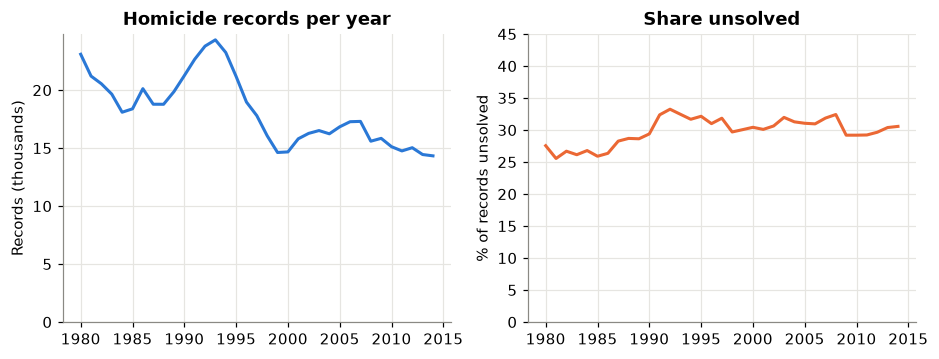

,homicides,unsolved_pct
Year,,
1980,23092,27.6
1990,21246,29.4
2000,14671,30.4
2010,15121,29.2
2014,14331,30.6


In [ ]:
by_year = raw.assign(unsolved=raw["Crime Solved"].eq("No")).groupby("Year").agg(
    homicides=("unsolved", "size"), unsolved_pct=("unsolved", "mean"))
by_year["unsolved_pct"] *= 100

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3.4))
ax0.plot(by_year.index, by_year["homicides"] / 1000, lw=2)
ax0.set_title("Homicide records per year"); ax0.set_ylabel("Records (thousands)"); ax0.set_ylim(0)
ax1.plot(by_year.index, by_year["unsolved_pct"], lw=2, color="orange")
ax1.set_title("Share unsolved"); ax1.set_ylabel("% of records unsolved"); ax1.set_ylim(0, 45)
plt.show();
by_year.iloc[[0, 10, 20, 30, -1]].round(1)

**Interpretation**: Recorded homicides fell from 23,092 in 1980 (peaking at 24,335 in 1993) to 14,331 in 2014, a drop of 38%, following the national drop in violence after the early-1990's peak. The share unsolved did not fall with it: it ranges from 25.6% (1981) to 33.3% (1992) and ends at 30.6% in 2014. Fewer homicides did not translate into better clearance. That is consistent with Hargrove's observation that clearance rates have been stuck for decades (Marshall Project interview, 2015). The stable target share is also good news for modelling: a model trained on earlier years should not face a very different class balance later, which 5.5 tests directly.

#### Who are the victims and whose cases go unsolved?


In [31]:
for col in ["Victim Race", "Victim Sex", "Victim Ethnicity", "Agency Type", "Weapon"]:
    df_to_show = unsolved_rate(raw, col).reset_index()
    display(df_to_show)

,Victim Race,n,unsolved_pct
0,Unknown,6676,46.2
1,Black,299899,33.7
2,Asian/Pacific Islander,9890,29.5
3,White,317422,25.9
4,Native American/Alaska Native,4567,20.1


,Victim Sex,n,unsolved_pct
0,Unknown,984,66.4
1,Male,494125,31.7
2,Female,143345,23.1


,Victim Ethnicity,n,unsolved_pct
0,Hispanic,72652,34.5
1,Unknown,368303,30.8
2,Not Hispanic,197499,26.3


,Agency Type,n,unsolved_pct
0,County Police,22693,33.2
1,Municipal Police,493026,31.8
2,Special Police,2889,28.8
3,Sheriff,105322,21.2
4,Regional Police,235,20.9
5,State Police,14235,17.7
6,Tribal Police,54,7.4


,Weapon,n,unsolved_pct
0,Firearm,46980,48.1
1,Strangulation,8110,45.6
2,Unknown,33192,44.5
3,Gun,2206,40.0
4,Fire,6173,32.9
5,Handgun,317484,31.7
6,Explosives,537,27.7
7,Suffocation,3968,24.9
8,Blunt Object,67337,23.5
9,Knife,94962,21.3


**Interpretation: who gets justice, before any adjustment**

- **Victim Race**: cases with Black victims are unsolved 33.7% of the time against 25.9% for White victims, a raw gap of 7.8 percentage points across about 300,000 victims in each group. Records with race "Unknown" are unsolved 46.2% of the time. This is probably not a group effect: when no one is identified, less is known about the victim too.
- **Victim Sex**: male victims 31.7% unsolved vs female victims 23.1%. Women are more often killed by partners or relatives, which makes the offender easier to identify.
- **Ethnicity**: Hispanic victims 34.5% vs 26.3% for non-Hispanic, but 58% of records have ethnicity "Unknown", so this comparison rests on a minority of records.
- **Agency Type**: municipal and county police forces (31.8%, 33.2%) leave far more cases unsolved than sheriff's offices (21.2%) and state police (17.7%). These forces serve cities, where homicides are more numerous and more often between strangers.
- **Weapon**: the least-solved categories are generic "Firearm" (48.1%), strangulation (45.6%) and "Unknown" (44.5%). Handguns (31.7%) are unsolved far more often than knives (21.3%), while rifles (14.6%) and shotguns (15.2%) are among the most solved. There is a recording-practice warning here: a vague weapon code ("Firearm", "Unknown") is more likely when nobody has been arrested to say what was used. Weapon detail is therefore partly a by-product of solving the case, a mild form of leakage I keep in mind when interpreting weapon effects.

These are associations. Black victims, men and handgun killings overlap heavily and are all concentrated in big-city police forces. The modelling stage separates them.

Victims aged 95-99: {95: 82, 96: 37, 97: 39, 98: 33, 99: 9281}


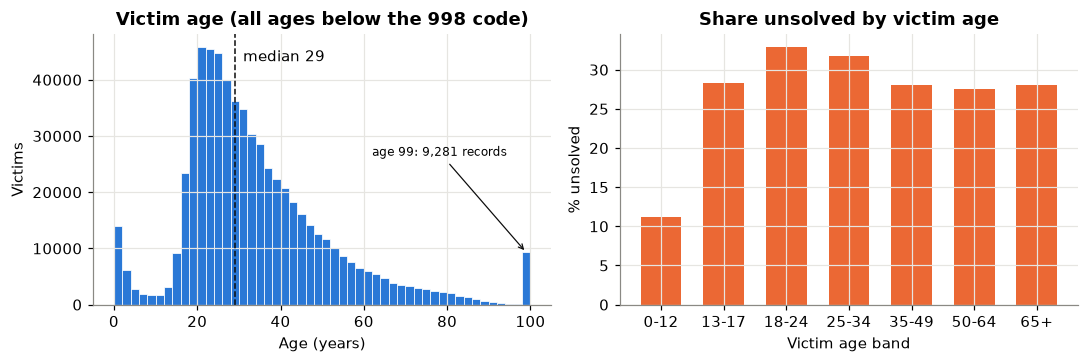

Mean 32.6, median 29, IQR 22-41


band
0-12     11.1
13-17    28.3
18-24    32.9
25-34    31.7
35-49    28.0
50-64    27.5
65+      28.0
Name: unsolved, dtype: float64

In [ ]:
# Victim age: 998 is a code, not an age. The histogram (ages < 998) shows a second suspicious spike at 99.
age_all = raw.loc[raw["Victim Age"] < 998, "Victim Age"]

print("Victims aged 95-99:", raw["Victim Age"].value_counts().sort_index().loc[95:99].to_dict())

age = raw.loc[raw["Victim Age"] < 99, "Victim Age"]  # 99 and 998 treated as 'unknown' codes from here on

bands = pd.cut(raw["Victim Age"].where(raw["Victim Age"] < 99), [-1, 12, 17, 24, 34, 49, 64, 120],
               labels=["0-12", "13-17", "18-24", "25-34", "35-49", "50-64", "65+"])

age_tab = raw.assign(band=bands, unsolved=raw["Crime Solved"].eq("No")).groupby("band", observed=True)["unsolved"].mean() * 100

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3.4))

ax0.hist(age_all, bins=np.arange(0, 101, 2), color="blue", edgecolor="white", linewidth=0.5)
ax0.axvline(age.median(), color="black", ls="--", lw=1); ax0.text(age.median() + 2, ax0.get_ylim()[1] * 0.9, f"median {age.median():.0f}")
ax0.annotate(f"age 99: {int((raw['Victim Age'] == 99).sum()):,} records", xy=(99, (raw["Victim Age"] == 99).sum()), xytext=(62, ax0.get_ylim()[1] * 0.55),
             arrowprops=dict(arrowstyle="->", color="black", lw=0.8), fontsize=8)
ax0.set_title("Victim age (all ages below the 998 code)"); 
ax0.set_xlabel("Age (years)"); 
ax0.set_ylabel("Victims")

ax1.bar(age_tab.index.astype(str), age_tab.values, color="orange", width=0.65)
ax1.set_title("Share unsolved by victim age"); 
ax1.set_ylabel("% unsolved"); 
ax1.set_xlabel("Victim age band")

fig.tight_layout(); 
plt.show();

print(f"Mean {age.mean():.1f}, median {age.median():.0f}, IQR {age.quantile(.25):.0f}-{age.quantile(.75):.0f}")
age_tab.round(1)

**Interpretation**: The histogram exposed a second hidden code, 9,281 victims are recorded as exactly 99, against only 33 aged 98 and 52% of those cases are unsolved. That is not a population of 99 year olds. It is an "age unknown" value (in the SHR, 99 also stands for "99 or older"). From here on 99 and 998 are both treated as missing. On real ages, victim age is right-skewed (mean 32.6 > median 29, IQR 22-41 years), with a spike at 0 for infants. Child victims (0-12) are rarely unsolved (11.1%) because they are usually killed by carers. The unsolved share peaks for young adults (18-24: 32.9%) and then declines gently (65+: 28.0%). Before removing the 99 code, the 65+ band appeared to rise to 33.5%, an artefact of the code that would have produced a false finding. The relationship is still not linear, so the random forest should capture it better than a single logistic coefficient.

In [34]:
# Two-way view: race x sex, and race x weapon group (firearm or not)
firearm = raw["Weapon"].isin(["Handgun", "Firearm", "Rifle", "Shotgun", "Gun"])
two_way = (raw.assign(unsolved=raw["Crime Solved"].eq("No"), firearm=np.where(firearm, "Firearm", "Other weapon"))
              .query("`Victim Race` in ['White', 'Black']")
              .pivot_table(index="Victim Race", columns=["Victim Sex", "firearm"], values="unsolved", aggfunc="mean") * 100)
two_way.round(1)

Victim Sex   Female                 Male              Unknown             
firearm     Firearm Other weapon Firearm Other weapon Firearm Other weapon
Victim Race                                                               
Black          23.5         30.8    38.0         25.0    66.7         42.3
White          13.7         26.3    28.9         26.0    46.2         52.4

**Interpretation**: The race gap is concentrated in firearm killings. For men killed without a firearm, cases with Black and White victims are unsolved at almost the same rate (25.0% vs 26.0%). For men killed with a firearm the gap is 9 points (38.0% vs 28.9%) and for women killed with a firearm it is 10 points (23.5% vs 13.7%). So the overall disparity is not uniform. It is the largest in the gun homicides that dominate urban violence. This motivated the firearm feature and the weapon comparison in 5.3 and it suggests a linear model without interactions will smooth over part of the story.

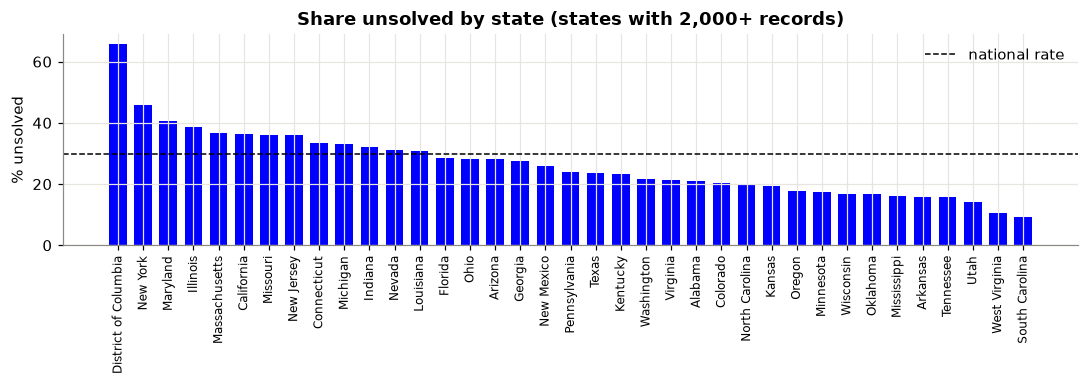

(                  State      n  unsolved_pct
 0  District of Columbia   7115          65.7
 1              New York  49268          45.9
 2              Maryland  17312          40.5
 3              Illinois  25871          38.8
 4         Massachusetts   6036          36.6,
              State      n  unsolved_pct
 32        Arkansas   6947          15.9
 33       Tennessee  14930          15.9
 34            Utah   2033          14.0
 35   West Virginia   3061          10.4
 36  South Carolina  11698           9.2)

In [43]:
# States: clearance varies widely. Show the states with at least 2,000 records.
st = unsolved_rate(raw, "State", min_n=2000).reset_index(drop = True)

fig, ax = plt.subplots(figsize=(10, 3.6))

ax.bar(st["State"], st["unsolved_pct"], color="blue", width=0.7)
ax.axhline(raw["Crime Solved"].eq("No").mean() * 100, color="black", ls="--", lw=1, label="national rate")
ax.set_ylabel("% unsolved"); 
ax.set_title("Share unsolved by state (states with 2,000+ records)")
ax.tick_params(axis="x", rotation=90, labelsize=8); 
ax.legend(frameon=False)
fig.tight_layout(); 

plt.show()
st.head(5), st.tail(5)

**Interpretation**: Geography matters more than any single victim attribute. Among states with 2,000+ records, the District of Columbia leaves 65.7% of homicides unsolved, New York 45.9%, Maryland 40.5% and Illinois 38.8%, while South Carolina (9.2%), West Virginia (10.4%) and Utah (14.0%) leave few unsolved. Part of this is real (large cities, gang violence, investigative capacity) and part may be reporting practice. Agencies differ in how promptly they update the SHR when a case is later solved. State is therefore kept as a control variable. Without it, the victim-race comparison would partly measure where Black and White victims live.

### 2.4 Data Quality Report 

In [44]:
# 1. 'Unknown' is the dataset's code for missing. Count it (and 998 / 0 ages) per column.
unknown = pd.DataFrame({
    "unknown_n": (raw.astype(str) == "Unknown").sum(),
}).assign(unknown_pct=lambda d: (d["unknown_n"] / len(raw) * 100).round(2))
unknown = unknown[unknown["unknown_n"] > 0].sort_values("unknown_pct", ascending=False)
display(unknown)
print("True NaN cells in the file:", int(raw.isna().sum().sum()))
print("Victim Age == 998 (unknown code):", int((raw["Victim Age"] == 998).sum()))
print("Victim Age == 0 (infants or a fill value?):", int((raw["Victim Age"] == 0).sum()))
print("Victim Age == 99:", int((raw["Victim Age"] == 99).sum()), "| aged 90-98 combined:", int(raw["Victim Age"].between(90, 98).sum()),
      "| unsolved % at 99:", round(raw.loc[raw["Victim Age"] == 99, "Crime Solved"].eq("No").mean() * 100, 1))
print("Victim Age > 99 but not 998:", int(((raw["Victim Age"] > 99) & (raw["Victim Age"] != 998)).sum()))

,unknown_n,unknown_pct
Perpetrator Ethnicity,446410,69.92
Victim Ethnicity,368303,57.69
Relationship,273013,42.76
Perpetrator Race,196047,30.71
Perpetrator Sex,190365,29.82
Weapon,33192,5.20
Victim Race,6676,1.05
Victim Sex,984,0.15
Agency Name,47,0.01


True NaN cells in the file: 0
Victim Age == 998 (unknown code): 974
Victim Age == 0 (infants or a fill value?): 8444
Victim Age == 99: 9281 | aged 90-98 combined: 1093 | unsolved % at 99: 52.0
Victim Age > 99 but not 998: 0


In [45]:
# 2. Types: Perpetrator Age should be numeric. Which values fail to convert?
pa = pd.to_numeric(raw["Perpetrator Age"], errors="coerce")
print("Perpetrator Age dtype as read:", raw["Perpetrator Age"].dtype)
print("Values that are not numbers:", raw.loc[pa.isna(), "Perpetrator Age"].value_counts().to_dict())
print("Perpetrator Age == 0:", int((pa == 0).sum()))

Perpetrator Age dtype as read: str
Values that are not numbers: {' ': 1}
Perpetrator Age == 0: 216327


In [46]:
# 3. Duplicates
print("Duplicate Record IDs:", raw["Record ID"].duplicated().sum())
print("Fully duplicated rows (ignoring Record ID):", raw.drop(columns="Record ID").duplicated().sum())

Duplicate Record IDs: 0
Fully duplicated rows (ignoring Record ID): 1768


In [47]:
# 4. LEAKAGE TEST: are offender fields filled in only when the case is solved?
display(pd.crosstab(raw["Perpetrator Sex"], raw["Crime Solved"], margins=True))
display(pd.crosstab(raw["Relationship"].eq("Unknown"), raw["Crime Solved"], normalize="columns").round(3)
          .rename(index={True: "Relationship Unknown", False: "Relationship known"}))
display(pd.crosstab(raw["Perpetrator Count"].clip(upper=2), raw["Crime Solved"]))

Crime Solved,No,Yes,All
Perpetrator Sex,,,
Female,5,48543,48548
Male,59,399482,399541
Unknown,190218,147,190365
All,190282,448172,638454


Crime Solved,No,Yes
Relationship,,
Relationship known,0.064,0.788
Relationship Unknown,0.936,0.212


Crime Solved,No,Yes
Perpetrator Count,,
0,184069,374769
1,5943,48802
2,270,24601


**Interpretation**: this is the most important finding of Data Undersanding. Perpetrator Sex is "Unknown" for 190,218 of the 190,282 unsolved cases (99.97%) and known for all but 147 solved cases. The offender fields do not predict the outcome, they encode it. A model given Perpetrator Sex would score almost perfectly and be useless. The same applies to Perpetrator Age (216,327 zeros, the "unknown" code), race and ethnicity and to Perpetrator Count. Relationship is "Unknown" in 93.6% of unsolved vs 21.2% of solved cases. The relationship is usually only learned through an investigation that finds the offender. All of these are excluded in Data Preparation because none would be known when a homicide is first reported.

The 64 unsolved cases with a recorded offender sex and the 147 solved cases without one are small inconsistencies (0.03%), possibly entry errors. They are left in place and listed in the quality report.

In [48]:
# 5. Inconsistency checks: 'City' really holds counties; ages under 18 for perpetrators of solved cases etc.
print("Example 'City' values:", raw["City"].value_counts().head(8).index.tolist())
print("Distinct City values:", raw["City"].nunique(), "| distinct agencies:", raw["Agency Code"].nunique())
print("Victim Count distribution:", raw["Victim Count"].value_counts().sort_index().head(6).to_dict())
print("Incident distribution (top):", raw["Incident"].value_counts().head(5).to_dict())
print("Victim Race counts:", raw["Victim Race"].value_counts().to_dict())

Example 'City' values: ['Los Angeles', 'New York', 'Cook', 'Wayne', 'Harris', 'Philadelphia', 'Dallas', 'Jefferson']
Distinct City values: 1782 | distinct agencies: 12003
Victim Count distribution: {0: 586059, 1: 38750, 2: 8156, 3: 2847, 4: 1084, 5: 510}
Incident distribution (top): {1: 265528, 2: 71779, 3: 39236, 4: 27113, 5: 20658}
Victim Race counts: {'White': 317422, 'Black': 299899, 'Asian/Pacific Islander': 9890, 'Unknown': 6676, 'Native American/Alaska Native': 4567}


#### Prioritised Quality Issues

| Priority | Issue | Evidence | Planned Action |
| ---- | ------------- | ------------------------------- | ------------------- |
| 1 | Target leakage in offender fields and relationship | Perpetrator Sex Unknown for 99.97% of unsolved cases, Relationship Unknown 93.6% unsolved vs 21.2% solved | Exclude from features |
| 2 | Victim age codes 998 and 999 = unknown | 974 + 9,281 values, 99 has 9,281 records vs 33 at age 98 and 52% unsolved. The mean is 35.0 with the codes vs 32.6 without them | Set both to missing and indicator, impute mean inside the pipeline (training data only) |
| 3 | "Unknown" categories | Victim Ethnicity 57.7%, Weapon 5.2%, Victim Race 1.05%, Victim Sex 0.15%, unsolved rates differ by Unknown status | Keep "Unknown" as its own level (informative missingness) |
| 4 | Mixed offence types | Negligent manslaughter: 9,116 rows, 4.3% unsolved | Exclude (different process) |
| 5 | Weapon detail partly recorded after the case is solved | Generic "Firearm" 48.1% unsolved, "Unknown" 44.5% | Keep, flag as possible mild leakage, check importance and discuss |
| 6 | Mislabelled/identifier columns | City holds 1,782 counties, Record ID, Agency Code, Incident are identifiers | Drop |
| 7 | Type Error | Perpetrator Age is stored as text because of one blank value | Column excluded for leakage | 
| 8 | Identical Rows | 1,768 rows identical apart from Record ID (same agency, month, incident number) | Investigate and keep, possibly multiple victims of one incident | 
| 9 | Coverage and Representativeness | Voluntary SHR reporting, state rates range from 9% to 66% unsolved | Control for State, record as a limitation |
| 10 | Victim age 0 | 8,444 values | Keep: infants (0-12 band has a plausible 11% unsolved rate) |


## 3. Data Preparation

Every action below is traceable to a finding in the Data Quality Report. The raw frame "raw" is never modified, all changes happen to a copy and every step is logged with the number of rows or values it affected.

In [49]:
df = raw.copy()
prep_log = []
def log(issue, action, rationale, assumption, affected, risk):
    prep_log.append({"Issue": issue, "Action": action, "Rationale / evidence": rationale,
                     "Assumption": assumption, "Number affected": affected, "Risk / verification": risk})
n0 = len(df)

In [50]:
# 3.1 SELECTION: keep murder / non-negligent manslaughter only
neg = df["Crime Type"].eq("Manslaughter by Negligence")
log("Negligent manslaughter mixed with murder", "Excluded 'Manslaughter by Negligence' rows",
    "Different offence, almost always solved (offender known at scene), see 2.3",
    "Oversight interest is in intentional killings", f"{neg.sum():,} rows ({neg.mean():.1%})",
    "Unsolved rate rises slightly, checked before/after in 3.6")
df = df.loc[~neg].copy()

In [51]:
# 3.2 SELECTION: drop leakage, identifier and redundant columns
leak = ["Perpetrator Sex", "Perpetrator Age", "Perpetrator Race", "Perpetrator Ethnicity", "Relationship", "Perpetrator Count"]
ids = ["Record ID", "Agency Code", "Agency Name", "City", "Incident", "Crime Type"]
log("Offender fields known only if solved (2.4 test 4)", "Dropped " + ", ".join(leak),
    "Perpetrator Sex is 'Unknown' for every unsolved case, using it would let the model read the answer",
    "Relationship is also recorded mainly after an arrest", f"{len(leak)} columns", "Model features checked in 4.1")
log("Identifiers and near-unique location fields", "Dropped " + ", ".join(ids),
    "Identifiers are not measurements, 'City' holds 1,782 county names (sparse, not a city), Crime Type now constant",
    "State + agency type capture location adequately", f"{len(ids)} columns", "Agency-level variation partly lost (limitation)")
df = df.drop(columns=leak + ids)

In [52]:
# 3.3 CLEANING: victim age codes
age998 = df["Victim Age"].isin([99, 998])
df["victim_age_missing"] = age998.astype(int)
df["Victim Age"] = df["Victim Age"].where(~age998)          # 99/998 -> NaN; imputed later inside the pipeline
log("Victim Age 998 and 99 = unknown codes", "Set to NaN + added victim_age_missing indicator, median imputation inside the model pipeline (fitted on training data only)",
    "998 would be read as a 998-year-old, 99 has 9,281 records vs 33 at age 98 and a 52% unsolved rate, so it is a code, not an age",
    "Unknown-age victims are otherwise comparable, a few genuine 99-year-olds are also set to missing", f"{age998.sum():,} values", "Indicator lets the model treat these separately, no leakage because the median is learned from training data")


In [53]:
# 3.4 CLEANING: 'Unknown' categories retained as their own level
unk = {c: int(df[c].eq("Unknown").sum()) for c in ["Victim Sex", "Victim Race", "Victim Ethnicity", "Weapon"]}
log("'Unknown' codes in victim race, sex, ethnicity and weapon", "Kept 'Unknown' as an explicit category (no mode imputation)",
    "Unknown rates differ between solved and unsolved cases, so absence is informative, mode imputation would inflate the majority group",
    "'Unknown' means not recorded, not a distinct population", str(unk), "Shown as its own coefficient in 5.3")

# 3.4b Duplicates and age 0: investigated, retained
dup = raw.drop(columns="Record ID").duplicated().sum()
log("Rows identical on every remaining field (2.4 test 3)", "Retained",
    "Record IDs are unique, identical rows share agency, month and incident number, i.e. several victims of one incident with the same recorded age/sex/race",
    "These are genuine separate victims, not double entries", f"{dup:,} rows", "Removing them would undercount multiple-victim incidents")
age0 = int(df["Victim Age"].eq(0).sum())
log("Victim Age = 0", "Retained as infants (under 1 year)",
    "SHR codes infants as 0, the 0-12 band has a distinct, low unsolved rate (11%), consistent with real child victims rather than a fill value",
    "0 is not used as a missing code for victims (99 and 998 are)", f"{age0:,} values", "Age band table in 2.3")

In [56]:
# 3.5 FEATURE CONSTRUCTION
firearms = ["Handgun", "Firearm", "Rifle", "Shotgun", "Gun"]
df["firearm"] = df["Weapon"].isin(firearms).astype(int)
df["multi_victim"] = df["Victim Count"].gt(0).astype(int)
df["unsolved"] = df["Crime Solved"].eq("No").astype(int)
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
df["Month"] = pd.Categorical(df["Month"], categories=month_order)
log("Weapon has 16 levels incl. 5 firearm types", "Constructed firearm = 1 if Handgun/Firearm/Rifle/Shotgun/Gun (Weapon kept too)",
    "Prior work finds firearm cases clear less often, one flag is easy to report", "Firearm subtypes behave similarly",
    f"{df['firearm'].sum():,} firearm cases", "Used in EDA and interpretation")
log("Victim Count counts *additional* victims", "Constructed multi_victim = Victim Count > 0",
    "Multiple-victim incidents may attract more investigative effort", "Value 0 = single victim",
    f"{df['multi_victim'].sum():,} rows", "Numeric Victim Count kept for the RF")
log("Target is text 'Yes'/'No'", "unsolved = 1 if Crime Solved == 'No' (positive class = unsolved)",
    "The event of interest is the failure to clear", "Agency status at time of reporting is the truth label",
    f"{df['unsolved'].sum():,} positives", "Class balance re-checked in 3.6")
df = df.drop(columns=["Crime Solved"])

In [57]:
# 3.6 VALIDATION: before/after profile
after = pd.DataFrame({
    "rows": [n0, len(df)],
    "columns": [raw.shape[1], df.shape[1]],
    "unsolved_%": [raw["Crime Solved"].eq("No").mean() * 100, df["unsolved"].mean() * 100],
    "Black victims_%": [raw["Victim Race"].eq("Black").mean() * 100, df["Victim Race"].eq("Black").mean() * 100],
    "female victims_%": [raw["Victim Sex"].eq("Female").mean() * 100, df["Victim Sex"].eq("Female").mean() * 100],
    "median victim age": [raw.loc[raw["Victim Age"] < 99, "Victim Age"].median(), df["Victim Age"].median()],
}, index=["raw", "prepared"]).round(2)
display(after)
print("Remaining NaN by column:", df.isna().sum()[df.isna().sum() > 0].to_dict())
print("Prepared columns:", df.columns.tolist())
df.to_csv(DATA / "homicides_prepared.csv", index=False)

,rows,columns,unsolved_%,Black victims_%,female victims_%,median victim age
raw,638454,24,29.80,46.97,22.45,29.0
prepared,629338,15,30.17,47.23,22.42,29.0


Remaining NaN by column: {'Victim Age': 10182}
Prepared columns: ['Agency Type', 'State', 'Year', 'Month', 'Victim Sex', 'Victim Age', 'Victim Race', 'Victim Ethnicity', 'Weapon', 'Victim Count', 'Record Source', 'victim_age_missing', 'firearm', 'multi_victim', 'unsolved']


**Validation**: Preparation removed 9,116 rows (1.4% all negligent manslaughter) and 9 columns. The unsolved share moved only from 29.80% to 30.17%. The shares of Black victims (46.97% to 47.23%) and female victims (22.45% to 22.42%) and the median victim age (29) are essentially unchanged, so the selection did not distort the groups the project compares. The only remaining NaN values are the 10,182 unknown ages (codes 99 and 998), which the model pipeline imputes from the training median. The raw data are untouched and the prepared file is saved seperately as data/homicides_prepared.csv.

### 3.7 Preparation Log 

In [58]:
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(prep_log)

,Issue,Action,Rationale / evidence,Assumption,Number affected,Risk / verification
0,Negligent manslaughter mixed with murder,Excluded 'Manslaughter by Negligence' rows,"Different offence, almost always solved (offender known at scene), see 2.3",Oversight interest is in intentional killings,"9,116 rows (1.4%)","Unsolved rate rises slightly, checked before/after in 3.6"
1,Offender fields known only if solved (2.4 test 4),"Dropped Perpetrator Sex, Perpetrator Age, Perpetrator Race, Perpetrator Ethnicity, Relationship, Perpetrator Count","Perpetrator Sex is 'Unknown' for every unsolved case, using it would let the model read the answer",Relationship is also recorded mainly after an arrest,6 columns,Model features checked in 4.1
2,Identifiers and near-unique location fields,"Dropped Record ID, Agency Code, Agency Name, City, Incident, Crime Type","Identifiers are not measurements, 'City' holds 1,782 county names (sparse, not a city), Crime Type now constant",State + agency type capture location adequately,6 columns,Agency-level variation partly lost (limitation)
3,Victim Age 998 and 99 = unknown codes,"Set to NaN + added victim_age_missing indicator, median imputation inside the model pipeline (fitted on training dat...","998 would be read as a 998-year-old, 99 has 9,281 records vs 33 at age 98 and a 52% unsolved rate, so it is a code, ...","Unknown-age victims are otherwise comparable, a few genuine 99-year-olds are also set to missing","10,182 values","Indicator lets the model treat these separately, no leakage because the median is learned from training data"
4,"'Unknown' codes in victim race, sex, ethnicity and weapon",Kept 'Unknown' as an explicit category (no mode imputation),"Unknown rates differ between solved and unsolved cases, so absence is informative, mode imputation would inflate the...","'Unknown' means not recorded, not a distinct population","{'Victim Sex': 973, 'Victim Race': 6630, 'Victim Ethnicity': 362785, 'Weapon': 31611}",Shown as its own coefficient in 5.3
5,Rows identical on every remaining field (2.4 test 3),Retained,"Record IDs are unique, identical rows share agency, month and incident number, i.e. several victims of one incident ...","These are genuine separate victims, not double entries","1,768 rows",Removing them would undercount multiple-victim incidents
6,Victim Age = 0,Retained as infants (under 1 year),"SHR codes infants as 0, the 0-12 band has a distinct, low unsolved rate (11%), consistent with real child victims ra...",0 is not used as a missing code for victims (99 and 998 are),"7,895 values",Age band table in 2.3
7,Weapon has 16 levels incl. 5 firearm types,Constructed firearm = 1 if Handgun/Firearm/Rifle/Shotgun/Gun (Weapon kept too),"Prior work finds firearm cases clear less often, one flag is easy to report",Firearm subtypes behave similarly,"415,031 firearm cases",Used in EDA and interpretation
8,Victim Count counts *additional* victims,Constructed multi_victim = Victim Count > 0,Multiple-victim incidents may attract more investigative effort,Value 0 = single victim,"52,018 rows",Numeric Victim Count kept for the RF
9,Target is text 'Yes'/'No',unsolved = 1 if Crime Solved == 'No' (positive class = unsolved),The event of interest is the failure to clear,Agency status at time of reporting is the truth label,"189,894 positives",Class balance re-checked in 3.6


## 4. Modelling

### 4.1 Task, features and split

- **Task:** binary classification. Positive class = unsolved (1)
- **Features** (all known when a homicide is first reported): victim sex, age-missing flag, race, ethnicity, weapon, firearm flag, victim count and multi victim flag, agency type, state, year, month, record source.
- **Excluded:** offender fields and relationship (leakage), identifiers.
- **Split:** stratified 80/20 train/test (random_state=42), so both sets keep the unsolved share. A second, time-based split (train 1980-2009, test 2010-2014) checks whether the patterns carry forward in time, which is the realistic situation for any future use.
- **Leakage control:** imputation, scaling and encoding sit inside scikit-learn pipelines, so medians, scales and category lists are learned from the training set only.

In [ ]:
num_cols = ["Year", "Victim Age", "victim_age_missing", "Victim Count", "multi_victim", "firearm"]
cat_cols = ["Victim Sex", "Victim Race", "Victim Ethnicity", "Weapon", "Agency Type", "State", "Month", "Record Source"]
X = df[num_cols + cat_cols]
y = df["unsolved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print(f"Train {len(X_train):,} | Test {len(X_test):,} | overlap: {len(set(X_train.index) & set(X_test.index))}")
pd.DataFrame({"train": y_train.value_counts(normalize=True), "test": y_test.value_counts(normalize=True)}).round(4)

### 4.2 Why the offender fields stay out: a deliberately leaky model

To show the leakage concretely and to record what my first plan would have produced, the cell below fits a logistic regression on only Perpetrator Sex and Relationship, using the same split. It is not used anywhere else.

In [ ]:
leak_X = raw.loc[df.index, ["Perpetrator Sex", "Relationship"]]
lX_tr, lX_te = leak_X.loc[X_train.index], leak_X.loc[X_test.index]
leaky = Pipeline([("oh", OneHotEncoder(handle_unknown="ignore")), ("clf", LogisticRegression(max_iter=1000))]).fit(lX_tr, y_train)
lp = leaky.predict_proba(lX_te)[:, 1]
print(f"Leaky model on test: accuracy {accuracy_score(y_test, lp >= .5):.4f} | recall {recall_score(y_test, lp >= .5):.4f} | "
      f"precision {precision_score(y_test, lp >= .5):.4f} | ROC AUC {roc_auc_score(y_test, lp):.4f}")

**Interpretation**: using just two offender-side fields, the model reaches 99.97% accuracy, 99.98% recall and ROC AUC 0.9998. Nothing about homicide investigation is being learned: Perpetrator Sex = Unknown is the definition of an unsolved case in this release. Any model or published analysis that includes these fields to "predict" clearance is reporting leakage, not insight. The honest models below have no access to them, which is why their scores are far low and far more meangingful.

### 4.3 Baseline

The majority-class baseline predicts "solved" for every case. Any useful model must find unsolved cases that this baseline misses.

In [ ]:
results = {}
def evaluate(name, y_true, pred, prob=None):
    results[name] = {"accuracy": accuracy_score(y_true, pred),
                     "precision": precision_score(y_true, pred, zero_division=0),
                     "recall": recall_score(y_true, pred, zero_division=0),
                     "f1": f1_score(y_true, pred, zero_division=0),
                     "roc_auc": roc_auc_score(y_true, prob) if prob is not None else 0.5}
    return pd.Series(results[name]).round(3)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
evaluate("Majority baseline", y_test, baseline.predict(X_test))

### 4.4 Primary model: logistic regression

Logistic regression is the primary model because its coefficients can be read as adjusted associations ("holding weapon, state, year... constant"), which is exactly what the business question needs. Categorical variables are one-hot encoded, numeric variables are median-imputed and standardised.

Two settings are compared:
- class_weight=None: the default. With 30% positives, the 0.5 threshold will be conservative.
- class_weight="balanced": errors on the minority class are up-weighted, which is equivalent to moving the threshold toward recall. This suits the oversight purpose, where missing an unsolved-prone group is worse than a false alarm.

In [ ]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop=None, min_frequency=50), cat_cols),
    ])

logit = Pipeline([("prep", make_preprocessor()),
                  ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]).fit(X_train, y_train)
logit_bal = Pipeline([("prep", make_preprocessor()),
                      ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))]).fit(X_train, y_train)

p_logit = logit.predict_proba(X_test)[:, 1]
p_logit_bal = logit_bal.predict_proba(X_test)[:, 1]
display(evaluate("Logistic regression", y_test, (p_logit >= 0.5).astype(int), p_logit))
display(evaluate("Logistic regression (balanced)", y_test, (p_logit_bal >= 0.5).astype(int), p_logit_bal))

**Interpretation:** the unweighted model is slightly more accurate than the baseline (0.712 vs 0.698), but at the default 0.5 threshold it finds only 17.8% of unsolved cases: with 30% positives, few cases get a predicted probability above 0.5. The balanced model trades accuracy (0.639) for recall of 0.664, finding two-thirds of unsolved cases with a precision of 0.435 (well above the 0.30 base rate). Both models have the same ROC AUC (0.695), as expected: class weighting mainly shifts the predicted probabilities so the cases are ranked in almost the same order. The real choice is where to set the threshold.

### 4.5 Alternative model: random forest

A random forest can capture interactions (for example, firearm killings being harder to clear in some states than others) that a linear model misses. Trees do not need scaling or one-hot encoding, so categories are ordinal-coded, which keeps training fast on 500,000 rows.

**Tuning**: hyperparameters are compared using the out-of-bag (OOB) score on a 100,000-row stratified sample of the training data, changing one setting at a time. The test set is not touched while tuning.

In [ ]:
rf_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
])
X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=min(100_000, len(X_train) // 2), random_state=RANDOM_STATE, stratify=y_train)
Xt = rf_prep.fit_transform(X_tune)

tuning = []
for leaf in [1, 5, 25, 100]:
    for mf in ["sqrt", 0.5]:
        rf = RandomForestClassifier(n_estimators=60, min_samples_leaf=leaf, max_features=mf, oob_score=True,
                                    class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE).fit(Xt, y_tune)
        oob_auc = roc_auc_score(y_tune, rf.oob_decision_function_[:, 1])
        tuning.append({"min_samples_leaf": leaf, "max_features": mf, "OOB accuracy": rf.oob_score_, "OOB ROC AUC": oob_auc,
                       "train ROC AUC": roc_auc_score(y_tune, rf.predict_proba(Xt)[:, 1])})
tuning = pd.DataFrame(tuning).round(3)
tuning

**Interpretation**: with min_samples_leaf=1 the trees memorise the training sample (training AUC 1.000) but the out-of-bag AUC is the worst in the grid (0.668-0.671): textbook overfitting. Larger leaves smooth the trees and OOB AUC rises to 0.721 at `min_samples_leaf=25` with `max_features=0.5`. Going to 100 starts to underfit (OOB 0.710-0.717). OOB accuracy barely changes and even falls as leaves grow because class weighting makes accuracy a poor guide here. AUC is used for selection. The chosen setting (25, 0.5) has a small train-OOB gap (0.787 vs 0.721), and `sqrt` at the same leaf size is within 0.004 so the choice is not fragile.

In [ ]:
best = tuning.sort_values("OOB ROC AUC", ascending=False).iloc[0]
best_leaf, best_mf = int(best["min_samples_leaf"]), best["max_features"]
best_mf = best_mf if best_mf == "sqrt" else float(best_mf)
print("Chosen:", best_leaf, best_mf)

forest = Pipeline([("prep", rf_prep),
                   ("clf", RandomForestClassifier(n_estimators=150, min_samples_leaf=best_leaf, max_features=best_mf,
                                                  max_samples=0.5, class_weight="balanced", n_jobs=-1,
                                                  random_state=RANDOM_STATE))]).fit(X_train, y_train)
p_rf = forest.predict_proba(X_test)[:, 1]
evaluate("Random forest (balanced)", y_test, (p_rf >= 0.5).astype(int), p_rf)

## 5. Evaluation

### 5.1 Technical performance against the baseline


In [ ]:
comparison = pd.DataFrame(results).T.round(3)
display(comparison)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (name, pred) in zip(axes, [("Majority baseline", baseline.predict(X_test)),
                                    ("Logistic regression (balanced)", (p_logit_bal >= .5).astype(int)),
                                    ("Random forest (balanced)", (p_rf >= .5).astype(int))]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Solved", "Unsolved"], cmap="Blues",
                                            colorbar=False, ax=ax, values_format=",")
    ax.set_title(name, fontsize=9); ax.grid(False)
fig.tight_layout(); 
plt.show()

**Interpretation against the success criteria**

- Both learned models clearly beat the baseline on the class that matters: baseline finds no unsolved cases, while the balanced logistic regression finds 66.4% and the random forest 65.8%.
- The random forest is the stronger classifier: ROC AUC 0.737 vs 0.695 and higher precision (0.476 vs 0.435) at similar recall. That fits the EDA, which found non-linear age effects and a race gap that depends on weapon. Interactions like these are what the forest can represent.
- The logistic regression narrowly misses the 0.70 AUC criterion (0.695). The forest meets it. Neither model is highly accurate in absolute terms. That is expected and important: the data contain nothing about witnesses, forensic evidence or detective workload, the factors prior studies find matter most [Wellford & Cronin 1999]. An AUC around 0.7 says these case characteristics are associated with clearance, not that clearance can be predicted for an individual case.
- The confusion matrices show the cost of the balanced models: about 32,700 (logistic) false positives, i.e. solved cases flagged as unsolved-prone. For a diagnostic use this is acceptable, for any case-level use it would not be.

### 5.2 Threshold trade-off


In [ ]:
def at_threshold(prob, t):
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"threshold": t, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred), "flagged_%": pred.mean() * 100, "false_negatives": fn, "false_positives": fp}
thr = pd.DataFrame([at_threshold(p_logit_bal, t) for t in [0.3, 0.4, 0.5, 0.6, 0.7]]).round(3)
thr

**Interpretation**: lowering the threshold to 0.3 finds 93.6% of unsolved cases but flags 84% of all cases so it no longer discriminates. Raising it to 0.7 gives the best precision (0.574) but finds only 17.5% of unsolved cases. F1 peaks at 0.5 (0.526) for the balanced model so 0.5 is kept. In an oversight setting the threshold decides how many case groups get reviewed. That is a resourcing decision for the stakeholder, not a statistical one, which is why the table shows the trade-off rather than a single "best" value.

### 5.3 Who gets justice? Adjusted gaps from the logistic model

Raw gaps mix together victim identity and case circumstances (for example, Black victims are more often killed with firearms, in large-city agencies with low clearance). To separate these, I use the fitted (unweighted) logistic model and ask a counterfactual question: *for every test case, what is the predicted probability of being unsolved if the victim were recorded as group A versus group B, keeping all other features as they are?* The average difference is the adjusted gap in percentage points. This is an association within the model, not a casual effect.

In [ ]:
def adjusted_gap(model, col, a, b, data=X_test):
    pa = model.predict_proba(data.assign(**{col: a}))[:, 1].mean()
    pb = model.predict_proba(data.assign(**{col: b}))[:, 1].mean()
    return pa, pb

rows = []
for col, a, b in [("Victim Race", "Black", "White"), ("Victim Sex", "Male", "Female"),
                  ("Victim Ethnicity", "Hispanic", "Not Hispanic")]:
    raw_a = y_test[X_test[col] == a].mean(); raw_b = y_test[X_test[col] == b].mean()
    pa, pb = adjusted_gap(logit, col, a, b)
    rows.append({"comparison": f"{col}: {a} vs {b}", "raw unsolved % (A)": raw_a * 100, "raw unsolved % (B)": raw_b * 100,
                 "raw gap (pp)": (raw_a - raw_b) * 100, "adjusted gap (pp)": (pa - pb) * 100})
# weapon: firearm flag and Weapon change together
fa = logit.predict_proba(X_test.assign(firearm=1, Weapon="Handgun"))[:, 1].mean()
fk = logit.predict_proba(X_test.assign(firearm=0, Weapon="Knife"))[:, 1].mean()
rows.append({"comparison": "Weapon: handgun vs knife", "raw unsolved % (A)": y_test[X_test["Weapon"] == "Handgun"].mean() * 100,
             "raw unsolved % (B)": y_test[X_test["Weapon"] == "Knife"].mean() * 100,
             "raw gap (pp)": (y_test[X_test["Weapon"] == "Handgun"].mean() - y_test[X_test["Weapon"] == "Knife"].mean()) * 100,
             "adjusted gap (pp)": (fa - fk) * 100})
gaps = pd.DataFrame(rows).round(1)
display(gaps)

fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.set_axisbelow(True)
yy = np.arange(len(gaps))
labels = ["Black vs White victim", "Male vs female victim", "Hispanic vs non-Hispanic", "Handgun vs knife"]
b1 = ax.barh(yy - 0.19, gaps["raw gap (pp)"], height=0.36, color=C["grey"], label="Raw gap")
b2 = ax.barh(yy + 0.19, gaps["adjusted gap (pp)"], height=0.36, color=C["blue"], label="Adjusted gap (logistic model)")
for bars in (b1, b2):
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8, color=C["ink"])
ax.set_yticks(yy, labels); ax.invert_yaxis(); ax.axvline(0, color=C["ink"], lw=0.8)
ax.set_xlim(0, 12.5)
ax.set_xlabel("Difference in % unsolved (percentage points)")
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "fig_gaps.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretation: the answer to "who gets justice?"**
- **Black vs White victims:** the raw test-set gap is 7.6 points (34.0% vs 26.4% unsolved). Holding weapon, state, agency type, year, month, victim age, sex and ethnicity constant, the model still estimates a gap of 6.3 points. Case circumstances explain only about one-sixth of the disparity. This is the same direction as Campdelli (2024), who reports an adjusted gap of 3.4-4.8 points with matching methods on MAP and NIBRS data. My larger estimate is plausible because I adjust for fewer variables (no county or agency, no circumstance code).
- **Male vs Female victims:** 8.7 raw to 6.3 adjusted.
- **Hispanic vs non-Hispanic:** 8.4 raw to 7.2 adjusted, but based only on the 42% of records where ethnicity is recorded, making this the least reliable of the comparisons.
- **Handgun vs knife:** 10.6 raw to 9.4 adjusted, the largest of the four, consistent with Jarvis et al. (2017), who find gun homicides clear more slowly than knife homicides.


Every gap shrinks once circumstances are controlled, but none disappear. These are adjusted associations, not casual effects. A remaining gap could reflect unequal investigative effort but also anything correlated with race that the data do not record: neighbourhood, witness cooperation, gang involvement or angency-level differences inside a state. The analysis shows where the inequality is, it cannot say why.

In [ ]:
names = logit.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({"feature": names, "coef": logit.named_steps["clf"].coef_[0]})
coefs["odds_ratio"] = np.exp(coefs["coef"])
sel = coefs[~coefs["feature"].str.contains("State_|Month_")].sort_values("coef")
pd.concat([sel.head(6), sel.tail(8)]).round(3)

**Interpretation:** Every category level is one-hot encoded and the model is L2-regularised, so the coefficients are compared with each other rather than against a single reference level.